# Week 9 matchup model: Jiffy jeffy vs. Jesus's Scary Team

**One file, runs offline.** The NFL data (2022 through 2026 Week 8, plus Week 9 lines and injury reports as of Thursday, Nov 5) is embedded in this notebook. Upload it to Rosie, open it, and use *Run → Run All Cells*. No internet or downloads needed.

**On Rosie:** launch *Jupyter Lab – Rosie* (or *Jupyter Notebook – Singularity*) from the web portal (dh-ood.hpc.msoe.edu → Interactive Apps), on the `teaching` partition with one T4. If XGBoost is installed (or can be installed), the models train on the GPU. If not, they fall back to scikit-learn on CPU and still finish in a few minutes. A second T4 adds nothing here, since each model trains on one GPU.

**What's inside**
1. Real game logs scored with your league's rules: full PPR, ESPN default D/ST and kicker scoring.
2. Gradient-boosted quantile models. Each player gets a full distribution (5th to 95th percentile) for the game, built only from information available before kickoff.
3. Hyperparameter tuning on 2025, then an honest test on 2026 Weeks 1–8 the model never saw.
4. Week 9 predictions for every player on **both** rosters, plus four D/ST options (Jaguars, Seahawks, Lions, Browns).
5. Correlations measured from history (QB and his receivers, RB vs. the defense he faces, etc.).
6. A 200,000-run simulation of the matchup that gives a **win probability for each lineup you could set**.
7. Boom/bust splits for each of your players.

**Limits:** weekly fantasy is mostly noise (expect ~4.5 points of average error per player). The model doesn't read news: depth-chart changes, snap limits, or a player going Out after Thursday's data snapshot. Check final injury reports before each game.

## Settings
Edit rosters and lineups here. Names must match nflverse spelling. D/ST uses team codes (JAX, SEA...). The Rams are `LA`, Washington is `WAS`.

In [1]:
CURRENT_SEASON = 2026
TARGET_WEEK = 9
SEASONS = [2022, 2023, 2024, 2025, 2026]
REFRESH_DATA = False        # True = download fresh data (needs internet + `pip install nflreadpy`)
N_SIMS = 200_000
QS = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]

MY_TEAM = "Jiffy jeffy"
MY_SKILL = ["J.J. McCarthy", "C.J. Stroud", "Kyren Williams", "Derrick Henry", "Rhamondre Stevenson",
            "Kyle Monangai", "Justin Jefferson", "Ladd McConkey", "Denzel Boston", "DeMario Douglas",
            "Keenan Allen", "Sam LaPorta"]
MY_DST = ["JAX", "SEA"]
FREE_AGENT_DST = ["DET", "CLE"]          # pickups being considered
MY_K = ["Spencer Shrader", "Tyler Bass"]

OPP_TEAM = "Jesus's Scary Team"
OPP_SKILL = ["Jayden Daniels", "James Cook", "Omarion Hampton", "Malik Nabers", "Zay Flowers", "Tucker Kraft",
             "Mike Evans", "Jakobi Meyers", "Rachaad White", "Devaughn Vele", "Tyler Allgeier", "Jaylen Warren"]
OPP_DST = ["MIN"]
OPP_K = ["Dominic Zvada", "Chris Boswell"]

# Lineups to compare. Slots: QB, RB1, RB2, WR1, WR2, TE, FLEX, DST, K
BASE = dict(QB="C.J. Stroud", RB1="Derrick Henry", RB2="Kyren Williams", WR1="Justin Jefferson",
            WR2="Denzel Boston", TE="Sam LaPorta", FLEX="Rhamondre Stevenson", K="Spencer Shrader")
MY_LINEUPS = {
    "Current ESPN lineup": dict(QB="J.J. McCarthy", RB1="Derrick Henry", RB2="Kyren Williams",
                                WR1="Justin Jefferson", WR2="Ladd McConkey", TE="Sam LaPorta",
                                FLEX="Rhamondre Stevenson", DST="SEA", K="Spencer Shrader"),
    "Model lineup + Seahawks D": {**BASE, "DST": "SEA"},
    "Model lineup + Jaguars D": {**BASE, "DST": "JAX"},
    "Model lineup + Lions D (pickup)": {**BASE, "DST": "DET"},
    "Model lineup + Browns D (pickup)": {**BASE, "DST": "CLE"},
    "Model lineup + Jaguars D, Rhamondre for Henry": {**BASE, "DST": "JAX", "RB1": "Rhamondre Stevenson",
                                                       "FLEX": "DeMario Douglas"},
}
# Opponent's lineup as shown on ESPN. "AUTO" = the model picks their best bench option (Evans is not practicing).
OPP_LINEUP = dict(QB="Jayden Daniels", RB1="James Cook", RB2="Omarion Hampton", WR1="Malik Nabers",
                  WR2="Zay Flowers", TE="Tucker Kraft", FLEX="AUTO", DST="MIN", K="Dominic Zvada")
OPP_OUT = ["Mike Evans", "Jaylen Warren", "Chris Boswell"]   # not expected to play (injury / bye)

ALL_SKILL, ALL_K = MY_SKILL + OPP_SKILL, MY_K + OPP_K
ALL_DST = MY_DST + FREE_AGENT_DST + OPP_DST

## Setup: packages and hardware

In [2]:
import importlib, json, shutil, subprocess, sys, time, warnings, zipfile, base64, io, glob, os
from pathlib import Path
warnings.filterwarnings("ignore")

def ensure(pkg, pip_name=None):
    try:
        return importlib.import_module(pkg)
    except ImportError:
        print(f"{pkg} missing, trying pip install --user {pip_name or pkg} ...")
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--user", "-q", pip_name or pkg],
                           capture_output=True, text=True)
        if r.returncode != 0:
            print(f"  could not install {pkg} (no internet?)")
            return None
        importlib.invalidate_caches()
        site = subprocess.run([sys.executable, "-m", "site", "--user-site"], capture_output=True, text=True).stdout.strip()
        if site and site not in sys.path:
            sys.path.append(site)
        try:
            return importlib.import_module(pkg)
        except ImportError:
            return None

for need in ["numpy", "pandas", "sklearn", "scipy", "matplotlib"]:
    assert ensure(need, "scikit-learn" if need == "sklearn" else None), f"{need} is required"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.ensemble import HistGradientBoostingRegressor

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

def ver(mod):
    return tuple(int("".join(ch for ch in x if ch.isdigit()) or 0) for x in mod.__version__.split(".")[:2])

def pip_upgrade(pip_name):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "--user", "-q", "--upgrade", pip_name],
                       capture_output=True, text=True)
    return r.returncode == 0

import sklearn
if ver(sklearn) < (1, 1):
    print(f"scikit-learn {sklearn.__version__} is too old (need 1.1+). Upgrading...")
    if pip_upgrade("scikit-learn"):
        raise SystemExit("scikit-learn upgraded. Restart the kernel (Kernel -> Restart) and Run All again.")
    raise SystemExit("Could not upgrade scikit-learn (no internet?). Pick a newer container image, "
                     "or use 'Jupyter Notebook - Rosie' instead.")

xgb = None if os.environ.get("FANTASY_BACKEND") == "sklearn" else ensure("xgboost")
if xgb is not None and ver(xgb) < (2, 0):
    print(f"XGBoost {xgb.__version__} is too old for quantile models (need 2.0+). Trying to upgrade...")
    if pip_upgrade("xgboost"):
        print("  upgraded. Restart the kernel and Run All to train on the GPU. Using scikit-learn on CPU for now.")
    else:
        print("  could not upgrade. Using scikit-learn on CPU (same conclusions, slower).")
    xgb = None
BACKEND, DEVICE = "sklearn", "cpu"
if xgb is not None:
    BACKEND = "xgboost"
    has_gpu = shutil.which("nvidia-smi") is not None and xgb.build_info().get("USE_CUDA", False)
    if has_gpu:
        try:
            xgb.XGBRegressor(n_estimators=3, tree_method="hist", device="cuda").fit(
                np.random.rand(500, 4), np.random.rand(500))
            DEVICE = "cuda"
        except Exception as e:
            print("GPU found but XGBoost could not use it, using CPU:", str(e)[:200])

print(f"Python {sys.version.split()[0]} | backend: {BACKEND} | device: {DEVICE}")
if shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv"],
                         capture_output=True, text=True).stdout)

Python 3.13.18 | backend: xgboost | device: cpu


## 1. Load data
Order of preference: fresh download (only if `REFRESH_DATA = True`), a `nfl_data/` folder or `nfl_data.zip` next to the notebook, then the copy embedded in this notebook's metadata.

In [3]:
DATA_DIR = Path("nfl_data")
NAMES = ["player_stats", "team_stats", "schedules", "injuries"]

def extract_embedded():
    for nb_path in sorted(glob.glob("*.ipynb"), key=os.path.getmtime, reverse=True):
        try:
            meta = json.load(open(nb_path)).get("metadata", {})
        except Exception:
            continue
        if "nfl_data_zip_b64" in meta:
            zipfile.ZipFile(io.BytesIO(base64.b64decode(meta["nfl_data_zip_b64"]))).extractall(".")
            print(f"Extracted embedded data from {nb_path} (snapshot: {meta.get('nfl_data_snapshot', '?')})")
            return True
    return False

if REFRESH_DATA:
    nfl = ensure("nflreadpy")
    DATA_DIR.mkdir(exist_ok=True)
    nfl.load_player_stats(SEASONS).to_pandas().to_csv(DATA_DIR / "player_stats.csv.gz", index=False)
    nfl.load_team_stats(SEASONS).to_pandas().to_csv(DATA_DIR / "team_stats.csv.gz", index=False)
    nfl.load_schedules(SEASONS).to_pandas().to_csv(DATA_DIR / "schedules.csv.gz", index=False)
    nfl.load_injuries([CURRENT_SEASON]).to_pandas().to_csv(DATA_DIR / "injuries.csv.gz", index=False)
elif not all((DATA_DIR / f"{n}.csv.gz").exists() for n in NAMES):
    if Path("nfl_data.zip").exists():
        zipfile.ZipFile("nfl_data.zip").extractall(".")
    elif not extract_embedded():
        raise FileNotFoundError("No data found. Keep this notebook's original file, add nfl_data.zip, "
                                "or set REFRESH_DATA = True.")

ps = pd.read_csv(DATA_DIR / "player_stats.csv.gz", low_memory=False)
ts = pd.read_csv(DATA_DIR / "team_stats.csv.gz")
sched = pd.read_csv(DATA_DIR / "schedules.csv.gz", low_memory=False)
inj = pd.read_csv(DATA_DIR / "injuries.csv.gz")

ps = ps[ps.season_type == "REG"].copy()
ts = ts[ts.season_type == "REG"].copy()
sched = sched[sched.game_type == "REG"].copy()
for df in (ps, ts):
    for c in ("team", "opponent_team"):
        df[c] = df[c].replace({"LAR": "LA"})
print("player games:", len(ps), "| team games:", len(ts),
      "| latest week with stats:", ps.loc[ps.season == CURRENT_SEASON, "week"].max())

Extracted embedded data from fantasy_week9_rosie.ipynb (snapshot: nflverse, 2022 through 2026 Week 8; Week 9 lines and injuries as of Thu Nov 5, 2026)


player games: 80885 | team games: 2416 | latest week with stats: 8


## 2. Game context: Vegas lines, home/away, weather, starting QBs
`team_spread` is positive when that team is favored. Implied points = (total ± spread) / 2.

In [4]:
home = sched.assign(team=sched.home_team, opp=sched.away_team, home=1, team_spread=sched.spread_line,
                    team_score=sched.home_score, opp_score=sched.away_score, opp_qb=sched.away_qb_name)
away = sched.assign(team=sched.away_team, opp=sched.home_team, home=0, team_spread=-sched.spread_line,
                    team_score=sched.away_score, opp_score=sched.home_score, opp_qb=sched.home_qb_name)
ctx = pd.concat([home, away], ignore_index=True)
ctx["implied_pts"] = (ctx.total_line + ctx.team_spread) / 2
ctx["opp_implied_pts"] = (ctx.total_line - ctx.team_spread) / 2
ctx["dome"] = ctx.roof.isin(["dome", "closed"]).astype(int)
ctx["wind"] = ctx.wind.fillna(0).where(ctx.dome == 0, 0)
ctx["temp"] = ctx.temp.fillna(70).where(ctx.dome == 0, 70)
ctx = ctx[["season", "week", "team", "opp", "home", "team_spread", "total_line", "implied_pts", "opp_implied_pts",
           "dome", "wind", "temp", "team_score", "opp_score", "opp_qb", "gameday", "gametime"]]
week_ctx = ctx.query("season == @CURRENT_SEASON and week == @TARGET_WEEK")
week_ctx.sort_values("implied_pts")[["team", "opp", "home", "team_spread", "total_line", "implied_pts",
                                     "opp_qb", "gameday", "gametime"]].reset_index(drop=True)

,team,opp,home,team_spread,total_line,implied_pts,opp_qb,gameday,gametime
0,BAL,JAX,1,-10.0,39.5,14.75,Trevor Lawrence,2026-11-05,20:15
1,ARI,SEA,0,-8.5,39.5,15.50,Drew Lock,2026-11-08,16:25
2,PHI,NYG,1,-3.5,38.5,17.50,J.J. McCarthy,2026-11-08,13:00
3,LAC,HOU,1,-4.5,40.5,18.00,C.J. Stroud,2026-11-08,16:05
4,NYJ,KC,0,-10.0,47.5,18.75,Patrick Mahomes,2026-11-08,13:00
5,CLE,NO,0,-3.0,42.5,19.75,Tyler Shough,2026-11-08,13:00
6,LV,SF,0,-10.0,51.5,20.75,Brock Purdy,2026-11-08,16:05
7,MIN,BUF,1,-3.0,44.5,20.75,Josh Allen,2026-11-09,20:15
8,TB,CHI,0,-6.0,47.5,20.75,Caleb Williams,2026-11-08,20:20
9,CAR,DEN,1,-2.5,44.5,21.00,Bo Nix,2026-11-08,13:00


## 3. ESPN-style D/ST and kicker scoring
- **D/ST:** sack 1, INT 2, fumble recovery 2, safety 2, blocked kick 2, TD 6. Points allowed 0 → +5, 1–6 → +4, 7–13 → +3, 14–17 → +1, 18–27 → 0, 28–34 → −1, 35–45 → −3, 46+ → −5. Yards allowed <100 → +5, 100–199 → +3, 200–299 → +2, 300–349 → 0, 350–399 → −1, 400–449 → −3, 450–499 → −5, 500–549 → −6, 550+ → −7.
- **K:** FG 0–39 = 3, 40–49 = 4, 50–59 = 5, 60+ = 6, PAT 1, missed FG or PAT −1.

D/ST is computed from team stats and can differ from ESPN by a point or two (ESPN excludes some points allowed, like pick-sixes thrown by the offense).

In [5]:
def pa_points(p):
    if pd.isna(p): return np.nan
    for hi, pts in [(0, 5), (6, 4), (13, 3), (17, 1), (27, 0), (34, -1), (45, -3)]:
        if p <= hi: return pts
    return -5

def ya_points(y):
    if pd.isna(y): return np.nan
    for hi, pts in [(99, 5), (199, 3), (299, 2), (349, 0), (399, -1), (449, -3), (499, -5), (549, -6)]:
        if y <= hi: return pts
    return -7

opp_off = ts[["season", "week", "team", "passing_yards", "rushing_yards", "sack_yards_lost"]].rename(
    columns={"team": "opponent_team", "passing_yards": "o_pass", "rushing_yards": "o_rush", "sack_yards_lost": "o_sack"})
dst = ts.merge(opp_off, on=["season", "week", "opponent_team"], how="left")
dst = dst.merge(ctx[["season", "week", "team", "opp_score"]], on=["season", "week", "team"], how="left")
dst["yards_allowed"] = dst.o_pass - dst.o_sack.fillna(0) + dst.o_rush
z = lambda c: dst[c].fillna(0)
dst["dst_pts"] = (z("def_sacks") + 2 * z("def_interceptions") + 2 * z("fumble_recovery_opp") + 2 * z("def_safeties")
                  + 2 * (z("def_punt_blocks") + z("def_fg_blocks") + z("def_pat_blocks"))
                  + 6 * (z("def_tds") + z("special_teams_tds"))
                  + dst.opp_score.apply(pa_points) + dst.yards_allowed.apply(ya_points))
dst = dst[["season", "week", "team", "opponent_team", "dst_pts"]]

k = ps[ps.position == "K"].copy()
f = lambda c: k[c].fillna(0)
k["k_pts"] = (3 * (f("fg_made_0_19") + f("fg_made_20_29") + f("fg_made_30_39")) + 4 * f("fg_made_40_49")
              + 5 * f("fg_made_50_59") + 6 * f("fg_made_60_") + f("pat_made") - f("fg_missed") - f("pat_missed"))

print("Check vs. ESPN season averages (ESPN: JAX 7.9, SEA 8.4, MIN 11.3, Shrader 11.0, Bass 11.1)")
print(dst.query("season == @CURRENT_SEASON and team in ['JAX','SEA','MIN','DET','CLE']").groupby("team").dst_pts.mean().round(1).to_dict())
print(k.query("season == @CURRENT_SEASON and player_display_name in @ALL_K").groupby("player_display_name").k_pts.mean().round(1).to_dict())

Check vs. ESPN season averages (ESPN: JAX 7.9, SEA 8.4, MIN 11.3, Shrader 11.0, Bass 11.1)
{'CLE': 4.6, 'DET': 2.4, 'JAX': 7.1, 'MIN': 9.6, 'SEA': 8.0}
{'Chris Boswell': 9.6, 'Dominic Zvada': 8.1, 'Spencer Shrader': 10.9, 'Tyler Bass': 10.9}


## 4. Features (all from before kickoff)
- Recent form: average PPR points over last 3 / last 8 / season to date, and volatility over last 8
- Usage: targets, carries, target share, WOPR, pass attempts (last 3)
- Opponent: PPR points allowed to the position per game (last 8) vs. league average
- Game: Vegas implied team total, spread, over/under, home, dome, wind, temperature

In [6]:
SKILL = ["QB", "RB", "WR", "TE"]
p = ps[ps.position.isin(SKILL)].copy()
p["fp"] = p.fantasy_points_ppr

last_seen = (p[p.season == CURRENT_SEASON].sort_values("week").groupby("player_id").tail(1)
             [["player_id", "player_display_name", "position", "team"]])
future = last_seen.merge(week_ctx[["team", "opp"]], on="team").rename(columns={"opp": "opponent_team"})
future = future.assign(season=CURRENT_SEASON, week=TARGET_WEEK, fp=np.nan)
p = pd.concat([p, future], ignore_index=True).sort_values(["player_id", "season", "week"]).reset_index(drop=True)

g = p.groupby("player_id")
roll = lambda s, n, mp=1: s.groupby(p.player_id).transform(lambda x: x.rolling(n, min_periods=mp).mean())
for col, src in [("fp", "fp"), ("tgt", "targets"), ("car", "carries"), ("tshare", "target_share"),
                 ("wopr", "wopr"), ("att", "attempts")]:
    p[f"{col}_l3"] = roll(g[src].shift(1), 3)
p["fp_l8"] = roll(g.fp.shift(1), 8)
p["fp_std_l8"] = g.fp.shift(1).groupby(p.player_id).transform(lambda x: x.rolling(8, min_periods=3).std())
p["fp_szn"] = p.groupby(["player_id", "season"]).fp.transform(lambda x: x.shift(1).expanding().mean())
p["games_prior"] = g.cumcount()

allowed = (p.dropna(subset=["fp"]).groupby(["season", "week", "opponent_team", "position"]).fp.sum()
           .reset_index().sort_values(["opponent_team", "position", "season", "week"]))
allowed["allowed_l8"] = allowed.groupby(["opponent_team", "position"]).fp.transform(
    lambda x: x.shift(1).rolling(8, min_periods=2).mean())
allowed["opp_pos_allowed"] = allowed.allowed_l8 - allowed.groupby(["season", "week", "position"]).allowed_l8.transform("mean")
tail8 = allowed.groupby(["opponent_team", "position"]).fp.apply(lambda x: x.tail(8).mean()).rename("v").reset_index()
tail8["opp_pos_allowed"] = tail8.v - tail8.groupby("position").v.transform("mean")
tail8 = tail8.assign(season=CURRENT_SEASON, week=TARGET_WEEK)
allowed = pd.concat([allowed, tail8[["season", "week", "opponent_team", "position", "opp_pos_allowed"]]])
allowed = allowed.drop_duplicates(["season", "week", "opponent_team", "position"], keep="last")

p = p.merge(allowed[["season", "week", "opponent_team", "position", "opp_pos_allowed"]],
            on=["season", "week", "opponent_team", "position"], how="left")
p = p.merge(ctx.drop(columns=["opp", "gameday", "gametime"]), on=["season", "week", "team"], how="left")
for pos in SKILL:
    p[f"is_{pos}"] = (p.position == pos).astype(int)

FEATURES = ["fp_l3", "fp_l8", "fp_szn", "fp_std_l8", "tgt_l3", "car_l3", "tshare_l3", "wopr_l3", "att_l3",
            "games_prior", "opp_pos_allowed", "implied_pts", "team_spread", "total_line",
            "home", "dome", "wind", "temp"] + [f"is_{x}" for x in SKILL]
hist = p.dropna(subset=["fp"]).query("games_prior >= 3")
print(len(hist), "training-eligible player games")

23197 training-eligible player games


## 5. The model
One quantile model per position group set predicts 7 percentiles at once. With XGBoost on the T4 this is a single multi-quantile model; with scikit-learn it's one model per percentile. Predictions are sorted so percentiles never cross.

In [7]:
class QuantileModel:
    def __init__(self, qs=QS, lr=0.05, depth=5, min_leaf=60, n_trees=350):
        self.qs, self.kw = np.array(qs), dict(lr=lr, depth=depth, min_leaf=min_leaf, n_trees=n_trees)

    def fit(self, X, y):
        kw = self.kw
        if BACKEND == "xgboost":
            self.m = xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=self.qs, tree_method="hist",
                                      device=DEVICE, n_estimators=kw["n_trees"], learning_rate=kw["lr"],
                                      max_depth=kw["depth"], min_child_weight=kw["min_leaf"], subsample=0.8,
                                      reg_lambda=2.0, random_state=0)
            try:
                self.m.fit(X, y)
            except Exception as e:
                if DEVICE != "cuda":
                    raise
                print("GPU training failed, retrying on CPU:", str(e)[:150])
                self.m.set_params(device="cpu"); self.m.fit(X, y)
        else:
            self.ms = [HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=kw["n_trees"],
                                                     learning_rate=kw["lr"], max_depth=kw["depth"],
                                                     min_samples_leaf=kw["min_leaf"], l2_regularization=1.0,
                                                     random_state=0).fit(X, y) for q in self.qs]
        return self

    def predict(self, X):
        out = self.m.predict(X) if BACKEND == "xgboost" else np.column_stack([m.predict(X) for m in self.ms])
        return np.sort(np.asarray(out).reshape(len(X), -1), axis=1)

def pinball(y, Q, qs=QS):
    y = np.asarray(y)[:, None]
    d = y - Q
    return np.mean(np.maximum(np.array(qs) * d, (np.array(qs) - 1) * d))

MED = QS.index(0.5)
LO, HI = QS.index(0.10), QS.index(0.90)

### 5a. Tune on 2025 (train 2022–2024)
This is where the GPU earns its keep: 12 configurations × 7 percentiles. The 2026 games stay untouched for the final test.

In [8]:
tr, va = hist[hist.season <= 2024], hist[hist.season == 2025]
grid = [dict(lr=lr, depth=d, min_leaf=ml) for lr in (0.03, 0.06) for d in (3, 5, 7) for ml in (40, 120)]
t0, results = time.time(), []
for cfg in grid:
    Q = QuantileModel(**cfg).fit(tr[FEATURES], tr.fp).predict(va[FEATURES])
    results.append({**cfg, "pinball": pinball(va.fp, Q), "median_MAE": np.mean(np.abs(va.fp - Q[:, MED]))})
tuning = pd.DataFrame(results).sort_values("pinball").reset_index(drop=True)
BEST = {k: tuning.loc[0, k] for k in ("lr", "depth", "min_leaf")}
BEST = {"lr": float(BEST["lr"]), "depth": int(BEST["depth"]), "min_leaf": int(BEST["min_leaf"])}
print(f"tuning took {time.time() - t0:.0f}s on {DEVICE} | best: {BEST}")
tuning.round(3).head(6)

tuning took 41s on cpu | best: {'lr': 0.06, 'depth': 3, 'min_leaf': 40}


,lr,depth,min_leaf,pinball,median_MAE
0,0.06,3,40,1.245,4.290
1,0.06,3,120,1.245,4.289
2,0.06,5,120,1.245,4.287
3,0.06,5,40,1.246,4.281
4,0.06,7,120,1.248,4.292
5,0.03,5,40,1.250,4.287


### 5b. Honest test: train through 2025, predict 2026 Weeks 1–8
Compared against what you'd do without a model. If the model doesn't beat these, ignore it.

In [9]:
train = hist[hist.season < CURRENT_SEASON]
test = hist[(hist.season == CURRENT_SEASON) & (hist.week < TARGET_WEEK)].copy()
Qt = QuantileModel(**BEST).fit(train[FEATURES], train.fp).predict(test[FEATURES])
test["model"] = Qt[:, MED]
base = test.fp_szn.fillna(test.fp_l8)

def pairwise_accuracy(df, col):
    hits = tot = 0
    for _, wk in df.groupby(["week", "position"]):
        v = wk[[col, "fp"]].to_numpy()
        if len(v) < 2: continue
        a, b = np.triu_indices(len(v), 1)
        dt = v[a, 1] - v[b, 1]; keep = dt != 0
        hits += (((v[a, 0] - v[b, 0]) > 0) == (dt > 0))[keep].sum(); tot += keep.sum()
    return hits / tot

rel = test.assign(baseline=base).query("fp_l8 >= 8")
summary = pd.DataFrame({
    "avg miss (MAE)": [np.mean(np.abs(test.fp - test.model)), np.mean(np.abs(test.fp - base)),
                       np.mean(np.abs(test.fp - test.fp_l3))],
    "picks higher scorer (8+ ppg players)": [pairwise_accuracy(rel, "model"), pairwise_accuracy(rel, "baseline"),
                                             pairwise_accuracy(rel.assign(l3=rel.fp_l3), "l3")],
}, index=["model (median)", "season average", "last 3 games"])
cover = np.mean((test.fp >= Qt[:, LO]) & (test.fp <= Qt[:, HI]))
print(f"2026 games inside the model's 10th–90th range: {cover:.0%} (should be ~80%) | test games: {len(test)}")
summary.assign(**{"picks higher scorer (8+ ppg players)": (100 * summary.iloc[:, 1]).round(1).astype(str) + "%"}).round(2)

2026 games inside the model's 10th–90th range: 80% (should be ~80%) | test games: 2476


,avg miss (MAE),picks higher scorer (8+ ppg players)
model (median),4.47,63.1%
season average,4.90,60.5%
last 3 games,4.87,59.6%


## 6. Week 9: every skill player on both rosters
Final model is refit on everything through Week 8. Floor = 10th percentile, ceiling = 90th.

In [10]:
fit_all = hist[(hist.season < CURRENT_SEASON) | (hist.week < TARGET_WEEK)]
skill_model = QuantileModel(**BEST).fit(fit_all[FEATURES], fit_all.fp)

wk = p.query("season == @CURRENT_SEASON and week == @TARGET_WEEK and player_display_name in @ALL_SKILL").copy()
SKILL_Q = dict(zip(wk.player_display_name, skill_model.predict(wk[FEATURES])))
wk["floor"] = [SKILL_Q[n][LO] for n in wk.player_display_name]
wk["median"] = [SKILL_Q[n][MED] for n in wk.player_display_name]
wk["ceiling"] = [SKILL_Q[n][HI] for n in wk.player_display_name]
inj_wk = inj.query("season == @CURRENT_SEASON and week == @TARGET_WEEK")[["full_name", "report_status", "practice_status"]]
wk = wk.merge(inj_wk.drop_duplicates("full_name"), left_on="player_display_name", right_on="full_name", how="left")
wk["fantasy_team"] = np.where(wk.player_display_name.isin(MY_SKILL), MY_TEAM, OPP_TEAM)

missing = set(MY_SKILL + OPP_SKILL) - set(wk.player_display_name)
print("No Week 9 game (bye) or not found:", missing or "none")
SKILL_TABLE = wk[["fantasy_team", "player_display_name", "position", "team", "opponent_team", "floor", "median",
                  "ceiling", "fp_szn", "fp_l3", "implied_pts", "opp_pos_allowed", "report_status",
                  "practice_status"]].sort_values(["fantasy_team", "position", "median"], ascending=[False, True, False])
SKILL_TABLE.round(1).reset_index(drop=True)

No Week 9 game (bye) or not found: {'Jaylen Warren'}


,fantasy_team,player_display_name,position,team,opponent_team,floor,median,ceiling,fp_szn,fp_l3,implied_pts,opp_pos_allowed,report_status,practice_status
0,Jiffy jeffy,C.J. Stroud,QB,HOU,LAC,5.3,16.4,26.299999,18.4,20.1,22.5,-3.2,NaN,NaN
1,Jiffy jeffy,J.J. McCarthy,QB,NYG,PHI,1.3,9.1,21.500000,8.9,8.9,21.0,2.7,NaN,NaN
2,Jiffy jeffy,Kyren Williams,RB,LA,WAS,6.2,15.7,28.500000,18.8,13.6,26.5,-2.1,NaN,NaN
3,Jiffy jeffy,Kyle Monangai,RB,CHI,TB,5.0,11.9,23.400000,14.8,13.0,26.8,-5.0,NaN,NaN
4,Jiffy jeffy,Rhamondre Stevenson,RB,NE,GB,3.8,11.7,23.600000,12.4,12.7,24.2,3.6,NaN,NaN
5,Jiffy jeffy,Derrick Henry,RB,BAL,JAX,5.3,11.3,22.799999,17.1,8.3,14.8,-4.8,NaN,NaN
6,Jiffy jeffy,Sam LaPorta,TE,DET,MIA,2.4,10.5,22.799999,12.3,9.7,28.8,4.6,NaN,NaN
7,Jiffy jeffy,Justin Jefferson,WR,MIN,BUF,4.8,12.2,24.900000,14.4,13.8,20.8,3.6,NaN,NaN
8,Jiffy jeffy,Keenan Allen,WR,IND,DAL,2.5,10.1,22.100000,10.6,12.0,23.0,4.7,NaN,Did Not Participate In Practice
9,Jiffy jeffy,Denzel Boston,WR,CLE,NO,2.9,9.8,20.799999,10.9,6.0,19.8,-1.6,NaN,Limited Participation in Practice


## 7. D/ST: your two plus the two free agents
Context columns show what drives D/ST scoring: the opponent's Vegas total, their starting QB, and how often they've allowed sacks and turnovers over their last 8 games.

In [11]:
d = dst.merge(ctx.drop(columns=["opp", "team_score", "opp_score", "gameday", "gametime"]), on=["season", "week", "team"], how="left")
up = week_ctx[["team", "opp"]].rename(columns={"opp": "opponent_team"}).assign(season=CURRENT_SEASON, week=TARGET_WEEK)
up = up.merge(ctx.drop(columns=["opp", "team_score", "opp_score", "gameday", "gametime"]), on=["season", "week", "team"])
d = pd.concat([d, up], ignore_index=True).sort_values(["team", "season", "week"]).reset_index(drop=True)
d["dst_l8"] = d.groupby("team").dst_pts.transform(lambda x: x.shift(1).rolling(8, min_periods=2).mean())

off = ts[["season", "week", "team", "sacks_suffered", "passing_interceptions", "fumbles_lost_total"]].merge(
    ctx[["season", "week", "team", "team_score"]], on=["season", "week", "team"]).sort_values(["team", "season", "week"])
OFF_COLS = ["sacks_suffered", "passing_interceptions", "fumbles_lost_total", "team_score"]
for c in OFF_COLS:
    off[f"opp_{c}_l8"] = off.groupby("team")[c].transform(lambda x: x.rolling(8, min_periods=2).mean())
off = off.rename(columns={"team": "opponent_team"})
# as-of join: each defense game gets the opponent offense's form from its games strictly before this week
d["key"] = d.season * 100 + d.week
off["key"] = off.season * 100 + off.week + 1
d = pd.merge_asof(d.sort_values("key"), off[["key", "opponent_team"] + [f"opp_{c}_l8" for c in OFF_COLS]].sort_values("key"),
                  on="key", by="opponent_team", direction="backward")

DST_FEATURES = ["dst_l8", "opp_implied_pts", "team_spread", "total_line", "home", "dome", "wind",
                "opp_sacks_suffered_l8", "opp_passing_interceptions_l8", "opp_fumbles_lost_total_l8", "opp_team_score_l8"]
dh = d.dropna(subset=["dst_pts"])
d_tr, d_te = dh[dh.season < CURRENT_SEASON], dh[(dh.season == CURRENT_SEASON) & (dh.week < TARGET_WEEK)]
dQ = QuantileModel(lr=0.04, depth=3, min_leaf=40, n_trees=250).fit(d_tr[DST_FEATURES], d_tr.dst_pts).predict(d_te[DST_FEATURES])
ok = d_te.dst_l8.notna()
print(f"D/ST 2026 avg miss — model: {np.mean(np.abs(d_te.dst_pts - dQ[:, MED])):.2f} | "
      f"last-8 average: {np.mean(np.abs(d_te.dst_pts[ok] - d_te.dst_l8[ok])):.2f}")

dst_model = QuantileModel(lr=0.04, depth=3, min_leaf=40, n_trees=250).fit(
    dh[(dh.season < CURRENT_SEASON) | (dh.week < TARGET_WEEK)][DST_FEATURES],
    dh[(dh.season < CURRENT_SEASON) | (dh.week < TARGET_WEEK)].dst_pts)
dw = d.query("season == @CURRENT_SEASON and week == @TARGET_WEEK and team in @ALL_DST").copy()
DST_Q = dict(zip(dw.team, dst_model.predict(dw[DST_FEATURES])))
for name, i in [("floor", LO), ("median", MED), ("ceiling", HI)]:
    dw[name] = [DST_Q[t][i] for t in dw.team]
dw["P(8+ pts)"] = [np.interp(8, DST_Q[t], QS, left=0, right=1) for t in dw.team]
dw["P(8+ pts)"] = 1 - dw["P(8+ pts)"]
dw["owner"] = np.select([dw.team.isin(MY_DST), dw.team.isin(OPP_DST)], ["you", "opponent"], "free agent")
DST_TABLE = dw[["team", "owner", "opponent_team", "opp_qb", "floor", "median", "ceiling", "P(8+ pts)", "dst_l8",
                "opp_implied_pts", "opp_sacks_suffered_l8", "opp_passing_interceptions_l8", "opp_fumbles_lost_total_l8"]]
DST_TABLE.sort_values("median", ascending=False).round(2).reset_index(drop=True)

D/ST 2026 avg miss — model: 4.10 | last-8 average: 4.57


,team,owner,opponent_team,opp_qb,floor,median,ceiling,P(8+ pts),dst_l8,opp_implied_pts,opp_sacks_suffered_l8,opp_passing_interceptions_l8,opp_fumbles_lost_total_l8
0,JAX,you,BAL,Joe Fagnano,0.44,7.73,15.88,0.48,8.00,14.75,2.75,0.38,0.62
1,SEA,you,ARI,Gardner Minshew,0.59,7.49,15.28,0.47,8.00,15.50,2.50,0.88,0.12
2,DET,free agent,MIA,Malik Willis,-0.47,4.83,11.65,0.22,2.88,21.75,3.12,0.75,0.62
3,MIN,opponent,BUF,Josh Allen,-3.06,4.05,11.00,0.21,9.62,23.75,1.62,0.62,0.75
4,CLE,free agent,NO,Tyler Shough,-2.24,3.30,11.44,0.20,4.62,22.75,2.38,0.88,1.00


## 8. Kickers

In [12]:
kk = k[["player_id", "player_display_name", "season", "week", "team", "opponent_team", "k_pts"]].copy()
k_last = kk[kk.season == CURRENT_SEASON].sort_values("week").groupby("player_id").tail(1)
k_future = k_last.drop(columns=["week", "k_pts", "opponent_team"]).merge(week_ctx[["team", "opp"]], on="team").rename(
    columns={"opp": "opponent_team"}).assign(week=TARGET_WEEK, k_pts=np.nan)
kk = pd.concat([kk, k_future], ignore_index=True).sort_values(["player_id", "season", "week"])
kk["k_l8"] = kk.groupby("player_id").k_pts.transform(lambda x: x.shift(1).rolling(8, min_periods=2).mean())
kk = kk.merge(ctx.drop(columns=["opp", "gameday", "gametime"]), on=["season", "week", "team"], how="left")
K_FEATURES = ["k_l8", "implied_pts", "team_spread", "total_line", "home", "dome", "wind", "temp"]
kh = kk.dropna(subset=["k_pts", "k_l8"])
k_tr, k_te = kh[kh.season < CURRENT_SEASON], kh[(kh.season == CURRENT_SEASON) & (kh.week < TARGET_WEEK)]
kQ = QuantileModel(lr=0.04, depth=3, min_leaf=40, n_trees=250).fit(k_tr[K_FEATURES], k_tr.k_pts).predict(k_te[K_FEATURES])
print(f"K 2026 avg miss — model: {np.mean(np.abs(k_te.k_pts - kQ[:, MED])):.2f} | last-8 average: {np.mean(np.abs(k_te.k_pts - k_te.k_l8)):.2f}")
k_model = QuantileModel(lr=0.04, depth=3, min_leaf=40, n_trees=250).fit(
    kh[(kh.season < CURRENT_SEASON) | (kh.week < TARGET_WEEK)][K_FEATURES],
    kh[(kh.season < CURRENT_SEASON) | (kh.week < TARGET_WEEK)].k_pts)
kw = kk.query("season == @CURRENT_SEASON and week == @TARGET_WEEK and player_display_name in @ALL_K").copy()
K_Q = dict(zip(kw.player_display_name, k_model.predict(kw[K_FEATURES])))
for name, i in [("floor", LO), ("median", MED), ("ceiling", HI)]:
    kw[name] = [K_Q[n][i] for n in kw.player_display_name]
kw["owner"] = np.where(kw.player_display_name.isin(MY_K), "you", "opponent")
kw[["player_display_name", "owner", "team", "opponent_team", "floor", "median", "ceiling", "k_l8", "implied_pts", "dome"]].round(1)

K 2026 avg miss — model: 3.83 | last-8 average: 4.05


,player_display_name,owner,team,opponent_team,floor,median,ceiling,k_l8,implied_pts,dome
1629,Tyler Bass,you,BUF,MIN,2.4,8.2,14.3,10.0,23.8,1
2306,Spencer Shrader,you,IND,DAL,2.1,8.7,14.4,10.9,23.0,0
2442,Dominic Zvada,opponent,NYG,PHI,2.7,8.1,15.1,8.1,21.0,0


## 9. How much do players' outcomes move together?
Measured from 2022–2025: correlation of each player's *surprise* (actual points minus his last-8 average) with another player's surprise in the same game. This is what makes stacking or splitting matter in the simulation.

In [13]:
hist_only = lambda df: df[(df.season < CURRENT_SEASON) | (df.week < TARGET_WEEK)]
sk = hist_only(p.dropna(subset=["fp", "fp_l8"])).query("games_prior >= 3 and fp_l8 >= 6").copy()
sk = sk[(sk.position != "QB") | (sk.att_l3 >= 20)]
sk["r"] = sk.fp - sk.fp_l8
sk = sk[["season", "week", "team", "opponent_team", "player_id", "position", "r"]]
dr = hist_only(d.dropna(subset=["dst_pts", "dst_l8"])).assign(r=lambda x: x.dst_pts - x.dst_l8)[["season", "week", "team", "opponent_team", "r"]]
kr = hist_only(kk.dropna(subset=["k_pts", "k_l8"])).assign(r=lambda x: x.k_pts - x.k_l8)[["season", "week", "team", "opponent_team", "player_id", "r"]]

def pc(a, b, la, rb, same=False):
    m = a.merge(b, left_on=["season", "week"] + la, right_on=["season", "week"] + rb, suffixes=("_a", "_b"))
    if same:
        m = m[m.player_id_a < m.player_id_b]
    return round(m.r_a.corr(m.r_b), 3), len(m)

QB, RB, PC = sk[sk.position == "QB"], sk[sk.position == "RB"], sk[sk.position.isin(["WR", "TE"])]
NONQB = sk[sk.position != "QB"]
CORR = {}
for key, args in {
    "QB & own WR/TE": (QB, PC, ["team"], ["team"]),
    "QB & own RB": (QB, RB, ["team"], ["team"]),
    "two own non-QBs": (NONQB, NONQB, ["team"], ["team"], True),
    "QB vs D/ST he faces": (QB, dr, ["opponent_team"], ["team"]),
    "RB vs D/ST he faces": (RB, dr, ["opponent_team"], ["team"]),
    "WR/TE vs D/ST he faces": (PC, dr, ["opponent_team"], ["team"]),
    "player & own D/ST": (sk, dr, ["team"], ["team"]),
    "players on opposite sides": (sk, sk, ["opponent_team"], ["team"]),
    "K & own skill player": (kr, sk, ["team"], ["team"]),
    "K vs D/ST he faces": (kr, dr, ["opponent_team"], ["team"]),
    "K & own D/ST": (kr, dr, ["team"], ["team"]),
    "two D/STs, same game": (dr, dr, ["opponent_team"], ["team"]),
}.items():
    CORR[key] = pc(*args)
pd.DataFrame(CORR, index=["correlation", "pairs"]).T

,correlation,pairs
QB & own WR/TE,0.295,6678.0
QB & own RB,0.051,3052.0
two own non-QBs,-0.002,20060.0
QB vs D/ST he faces,-0.412,2131.0
RB vs D/ST he faces,-0.249,3295.0
WR/TE vs D/ST he faces,-0.189,7161.0
player & own D/ST,-0.047,12587.0
players on opposite sides,0.043,68286.0
K & own skill player,0.052,12231.0
K vs D/ST he faces,-0.258,2284.0


## 10. Matchup simulation
Each run draws every player's score from his model distribution, linked by the correlations above (Gaussian copula). The same draws are used for every lineup, so differences between lineups are real, not sampling noise.

In [14]:
OPP_AUTO = None
if OPP_LINEUP.get("FLEX") == "AUTO":
    used = {v for k_, v in OPP_LINEUP.items() if k_ not in ("FLEX", "DST", "K")}
    cand = SKILL_TABLE[(SKILL_TABLE.fantasy_team == OPP_TEAM) & ~SKILL_TABLE.player_display_name.isin(used | set(OPP_OUT))
                       & SKILL_TABLE.position.isin(["RB", "WR", "TE"])]
    OPP_AUTO = cand.sort_values("median", ascending=False).player_display_name.iloc[0]
    OPP_LINEUP = {**OPP_LINEUP, "FLEX": OPP_AUTO}
print("Opponent FLEX (replacing Evans):", OPP_AUTO)

info = SKILL_TABLE.set_index("player_display_name")
ents = {}
for n in set(sum([list(v.values()) for v in MY_LINEUPS.values()], []) + list(OPP_LINEUP.values())):
    if n in SKILL_Q:
        ents[n] = dict(kind="skill", pos=info.loc[n, "position"], team=info.loc[n, "team"], opp=info.loc[n, "opponent_team"], q=SKILL_Q[n], low=-2)
    elif n in DST_Q:
        o = dw.set_index("team").loc[n, "opponent_team"]
        ents[n] = dict(kind="dst", pos="DST", team=n, opp=o, q=DST_Q[n], low=-6)
    elif n in K_Q:
        r = kw.set_index("player_display_name").loc[n]
        ents[n] = dict(kind="k", pos="K", team=r.team, opp=r.opponent_team, q=K_Q[n], low=-2)
    else:
        raise KeyError(f"{n} has no Week 9 prediction (bye? misspelled?)")
names = sorted(ents)

def rho(a, b):
    A, B = ents[a], ents[b]
    c = lambda key: CORR[key][0]
    kinds = {A["kind"], B["kind"]}
    same, faces_ab, faces_ba = A["team"] == B["team"], A["opp"] == B["team"], B["opp"] == A["team"]
    if kinds == {"skill"}:
        if same:
            ps_ = {A["pos"], B["pos"]}
            if "QB" in ps_: return c("QB & own WR/TE") if ps_ & {"WR", "TE"} else c("QB & own RB")
            return c("two own non-QBs")
        return c("players on opposite sides") if faces_ab else 0.0
    if kinds == {"skill", "dst"}:
        S, D = (A, B) if A["kind"] == "skill" else (B, A)
        if S["opp"] == D["team"]:
            return c({"QB": "QB vs D/ST he faces", "RB": "RB vs D/ST he faces"}.get(S["pos"], "WR/TE vs D/ST he faces"))
        return c("player & own D/ST") if S["team"] == D["team"] else 0.0
    if kinds == {"skill", "k"}:
        return c("K & own skill player") if same else 0.0
    if kinds == {"k", "dst"}:
        K_, D = (A, B) if A["kind"] == "k" else (B, A)
        if K_["opp"] == D["team"]: return c("K vs D/ST he faces")
        return c("K & own D/ST") if K_["team"] == D["team"] else 0.0
    if kinds == {"dst"}:
        return c("two D/STs, same game") if faces_ab else 0.0
    return 0.0

n_ = len(names)
C = np.eye(n_)
for i in range(n_):
    for j in range(i + 1, n_):
        C[i, j] = C[j, i] = rho(names[i], names[j])
w, V = np.linalg.eigh(C)
C = V @ np.diag(np.clip(w, 1e-6, None)) @ V.T
C = C / np.sqrt(np.outer(np.diag(C), np.diag(C)))

rng = np.random.default_rng(9)
U = norm.cdf(rng.standard_normal((N_SIMS, n_)) @ np.linalg.cholesky(C).T)
xs = np.r_[0.0, QS, 1.0]
def draw(e, u):
    q = e["q"]
    ys = np.r_[max(e["low"], q[0] - 2 * (q[1] - q[0])), q, q[-1] + 2 * (q[-1] - q[-2])]
    return np.interp(u, xs, ys)
SIM = {nm: draw(ents[nm], U[:, i]) for i, nm in enumerate(names)}

opp_total = sum(SIM[v] for v in OPP_LINEUP.values())
rows = []
for label, lu in MY_LINEUPS.items():
    tot = sum(SIM[v] for v in lu.values())
    rows.append({"lineup": label, "win %": np.mean(tot > opp_total) * 100, "median pts": np.median(tot),
                 "10th pct": np.percentile(tot, 10), "90th pct": np.percentile(tot, 90),
                 "median margin": np.median(tot - opp_total)})
MATCHUP = pd.DataFrame(rows).sort_values("win %", ascending=False).reset_index(drop=True)
print(f"Opponent ({OPP_TEAM}) median {np.median(opp_total):.1f}, 10th–90th: {np.percentile(opp_total, 10):.1f}–{np.percentile(opp_total, 90):.1f}")
MATCHUP.round(1)

Opponent FLEX (replacing Evans): Devaughn Vele


Opponent (Jesus's Scary Team) median 106.7, 10th–90th: 80.2–135.0


,lineup,win %,median pts,10th pct,90th pct,median margin
0,Model lineup + Jaguars D,56.3,111.5,84.7,140.1,4.9
1,Model lineup + Seahawks D,56.3,111.4,84.4,140.5,4.8
2,Model lineup + Lions D (pickup),52.9,108.9,82.0,137.7,2.2
3,"Model lineup + Jaguars D, Rhamondre for Henry",52.8,108.7,81.7,137.6,2.1
4,Model lineup + Browns D (pickup),51.4,107.7,80.8,136.7,1.1
5,Current ESPN lineup,44.5,102.5,76.0,131.6,-4.0


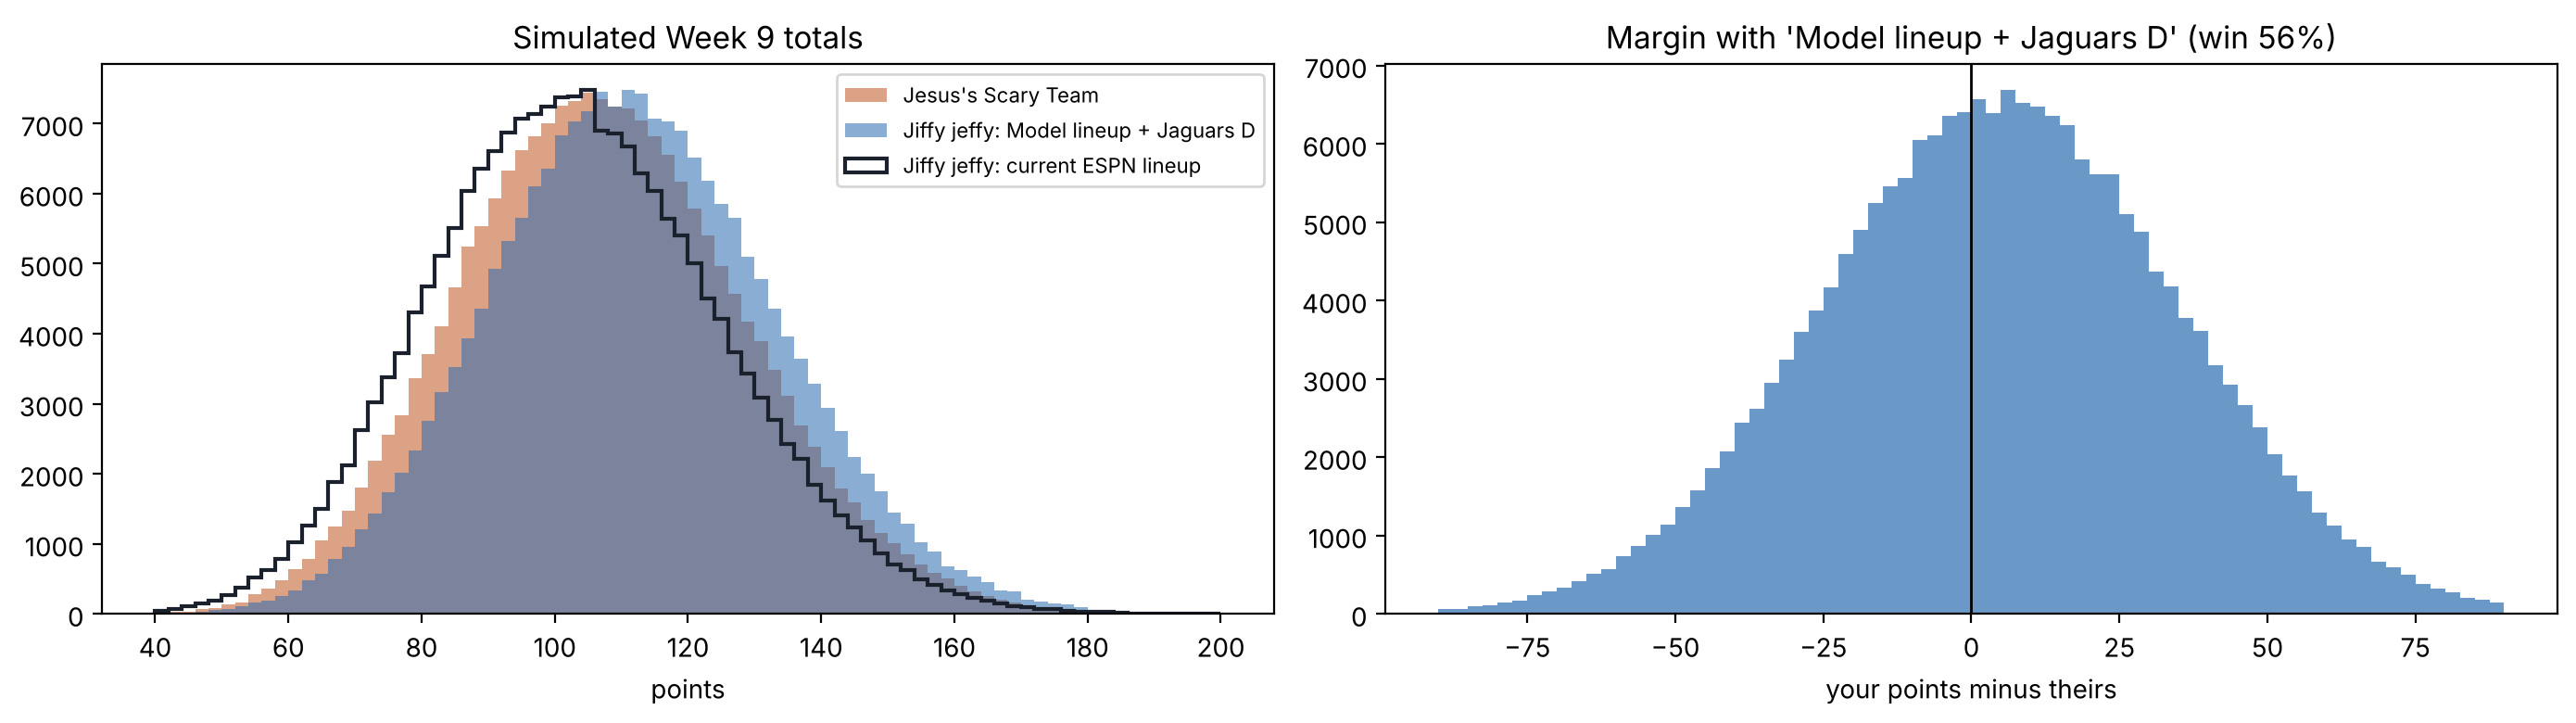

In [15]:
best = MATCHUP.lineup.iloc[0]
mine = sum(SIM[v] for v in MY_LINEUPS[best].values())
cur = sum(SIM[v] for v in MY_LINEUPS["Current ESPN lineup"].values())
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
bins = np.linspace(40, 200, 81)
ax[0].hist(opp_total, bins, alpha=0.55, label=OPP_TEAM, color="#c05621")
ax[0].hist(mine, bins, alpha=0.55, label=f"{MY_TEAM}: {best}", color="#2b6cb0")
ax[0].hist(cur, bins, histtype="step", lw=1.5, label=f"{MY_TEAM}: current ESPN lineup", color="#1a202c")
ax[0].set_title("Simulated Week 9 totals"); ax[0].set_xlabel("points"); ax[0].legend(fontsize=8)
ax[1].hist(mine - opp_total, np.linspace(-90, 90, 73), color="#2b6cb0", alpha=0.7)
ax[1].axvline(0, color="black", lw=1)
ax[1].set_title(f"Margin with '{best}' (win {np.mean(mine > opp_total):.0%})"); ax[1].set_xlabel("your points minus theirs")
plt.tight_layout(); plt.show()

### Player-by-player for both lineups
`P(beats median)` uses the simulation, so it includes each player's own spread. Slots are lined up against the opponent's player in the same slot.

In [16]:
def lineup_table(lu, who):
    out = []
    for slot, n in lu.items():
        s = SIM[n]
        out.append({"team": who, "slot": slot, "player": n, "floor": np.percentile(s, 10), "median": np.median(s),
                    "ceiling": np.percentile(s, 90), "P(15+)": np.mean(s >= 15)})
    return pd.DataFrame(out)
SLOTS = lineup_table(MY_LINEUPS[best], MY_TEAM).merge(
    lineup_table(OPP_LINEUP, OPP_TEAM), on="slot", suffixes=("", " (opp)"))
SLOTS["edge"] = SLOTS["median"] - SLOTS["median (opp)"]
SLOTS[["slot", "player", "floor", "median", "ceiling", "player (opp)", "floor (opp)", "median (opp)", "ceiling (opp)", "edge"]].round(1)

,slot,player,floor,median,ceiling,player (opp),floor (opp),median (opp),ceiling (opp),edge
0,QB,C.J. Stroud,5.3,16.4,26.3,Jayden Daniels,6.3,16.6,26.9,-0.2
1,RB1,Derrick Henry,5.3,11.4,22.9,James Cook,6.3,15.4,26.4,-4.0
2,RB2,Kyren Williams,6.2,15.7,28.5,Omarion Hampton,1.6,8.0,17.8,7.7
3,WR1,Justin Jefferson,4.8,12.2,24.9,Malik Nabers,5.5,13.9,26.7,-1.7
4,WR2,Denzel Boston,2.9,9.9,20.9,Zay Flowers,5.2,12.9,27.6,-3.0
5,TE,Sam LaPorta,2.4,10.5,22.7,Tucker Kraft,2.6,9.6,21.4,0.9
6,FLEX,Rhamondre Stevenson,3.8,11.7,23.6,Devaughn Vele,2.6,10.1,22.0,1.6
7,K,Spencer Shrader,2.1,8.6,14.4,Dominic Zvada,2.8,8.1,15.2,0.6
8,DST,JAX,0.5,7.7,15.9,MIN,-3.0,4.0,11.0,3.7


## 11. When each of your players does well and when they don't (2025–26)
Each player's games are split into best third ("boom") and worst third ("bust"), with the conditions in each. Samples are small (6–9 games per group): a gap is a lead, not a rule. "Opp D softness" is points allowed to the position above league average (positive = weak defense).

In [17]:
recent = p.dropna(subset=["fp"]).query("season >= 2025 and player_display_name in @MY_SKILL").copy()
rows = []
for name, gdf in recent.groupby("player_display_name"):
    if len(gdf) < 6: continue
    lo_c, hi_c = gdf.fp.quantile([1 / 3, 2 / 3])
    boom, bust = gdf[gdf.fp >= hi_c], gdf[gdf.fp <= lo_c]
    t = lambda x: (x.targets.fillna(0) + x.carries.fillna(0)).mean()
    rows.append({"player": name, "games": len(gdf), "boom avg": boom.fp.mean(), "bust avg": bust.fp.mean(),
                 "home% boom": 100 * boom.home.mean(), "home% bust": 100 * bust.home.mean(),
                 "team total boom": boom.implied_pts.mean(), "team total bust": bust.implied_pts.mean(),
                 "favored% boom": 100 * (boom.team_spread > 0).mean(), "favored% bust": 100 * (bust.team_spread > 0).mean(),
                 "opp D softness boom": boom.opp_pos_allowed.mean(), "opp D softness bust": bust.opp_pos_allowed.mean(),
                 "touches boom": t(boom), "touches bust": t(bust)})
pd.DataFrame(rows).set_index("player").round(1)

,games,boom avg,bust avg,home% boom,home% bust,team total boom,team total bust,favored% boom,favored% bust,opp D softness boom,opp D softness bust,touches boom,touches bust
player,,,,,,,,,,,,,
C.J. Stroud,21,22.8,9.8,57.1,28.6,23.1,21.4,85.7,42.9,-0.3,0.6,3.9,2.9
DeMario Douglas,24,14.5,2.2,62.5,37.5,24.5,22.7,87.5,25.0,-2.0,0.0,5.5,2.4
Denzel Boston,8,16.0,5.4,0.0,66.7,16.8,18.9,0.0,33.3,-1.0,4.9,6.0,5.7
Derrick Henry,25,26.4,8.2,33.3,55.6,24.5,24.9,77.8,77.8,-1.1,-0.6,24.0,16.6
J.J. McCarthy,13,20.3,3.5,40.0,60.0,21.2,22.2,20.0,60.0,1.2,1.9,4.6,2.2
Justin Jefferson,23,19.5,5.8,25.0,50.0,22.0,20.7,87.5,25.0,1.0,4.0,9.5,6.2
Keenan Allen,24,18.0,4.9,75.0,50.0,23.1,22.5,62.5,62.5,2.5,-0.6,9.8,4.5
Kyle Monangai,21,18.7,2.9,57.1,57.1,23.8,21.8,85.7,14.3,2.8,-0.1,19.7,7.4
Kyren Williams,25,23.2,10.3,33.3,55.6,26.0,26.7,77.8,88.9,-1.1,2.0,20.9,17.4


In [18]:
def splits(x):
    parts = {"home": x.home == 1, "away": x.home == 0, "favored": x.team_spread > 0, "underdog": x.team_spread < 0,
             "team total 24+": x.implied_pts >= 24, "team total <21": x.implied_pts < 21,
             "soft D": x.opp_pos_allowed > 0, "tough D": x.opp_pos_allowed < 0, "dome": x.dome == 1, "outdoors": x.dome == 0}
    return {k_: (f"{x.fp[m].mean():.1f} ({m.sum()})" if m.sum() else "—") for k_, m in parts.items()}
print("Average PPR points (games) under each condition, 2025–26")
pd.DataFrame({n: splits(x) for n, x in recent.groupby("player_display_name")}).T

Average PPR points (games) under each condition, 2025–26


,home,away,favored,underdog,team total 24+,team total <21,soft D,tough D,dome,outdoors
C.J. Stroud,16.8 (11),15.3 (10),17.7 (13),13.4 (8),18.3 (5),13.5 (6),16.0 (11),16.1 (10),15.4 (14),17.3 (7)
DeMario Douglas,8.9 (11),6.0 (13),10.1 (14),3.6 (10),12.0 (10),7.0 (1),6.4 (9),8.0 (15),16.1 (1),7.0 (23)
Denzel Boston,7.8 (3),12.7 (5),5.7 (1),11.6 (7),—,10.9 (8),7.9 (4),13.8 (4),—,10.9 (8)
Derrick Henry,14.1 (12),19.0 (13),16.1 (19),18.3 (6),16.6 (17),22.5 (4),16.9 (7),16.5 (18),23.3 (2),16.1 (23)
J.J. McCarthy,11.4 (6),12.0 (7),9.5 (5),13.1 (8),5.6 (3),7.4 (4),10.8 (8),13.2 (5),13.1 (8),9.5 (5)
Justin Jefferson,12.3 (10),12.7 (13),15.7 (12),9.1 (11),16.0 (5),11.2 (6),12.5 (16),12.5 (7),12.8 (15),12.0 (8)
Keenan Allen,12.5 (12),8.9 (12),11.2 (13),10.2 (11),11.9 (12),9.2 (8),13.4 (14),7.0 (10),11.4 (13),9.9 (11)
Kyle Monangai,9.3 (11),10.3 (10),13.8 (10),6.2 (11),11.6 (9),8.8 (4),11.0 (11),8.5 (10),5.7 (3),10.5 (18)
Kyren Williams,15.5 (13),17.6 (12),16.4 (22),17.5 (3),16.2 (18),11.5 (1),16.0 (14),17.2 (11),15.8 (16),17.8 (9)
Ladd McConkey,12.7 (11),8.5 (11),12.3 (14),7.5 (8),13.7 (13),4.3 (5),11.2 (10),10.0 (12),12.6 (14),7.0 (8)


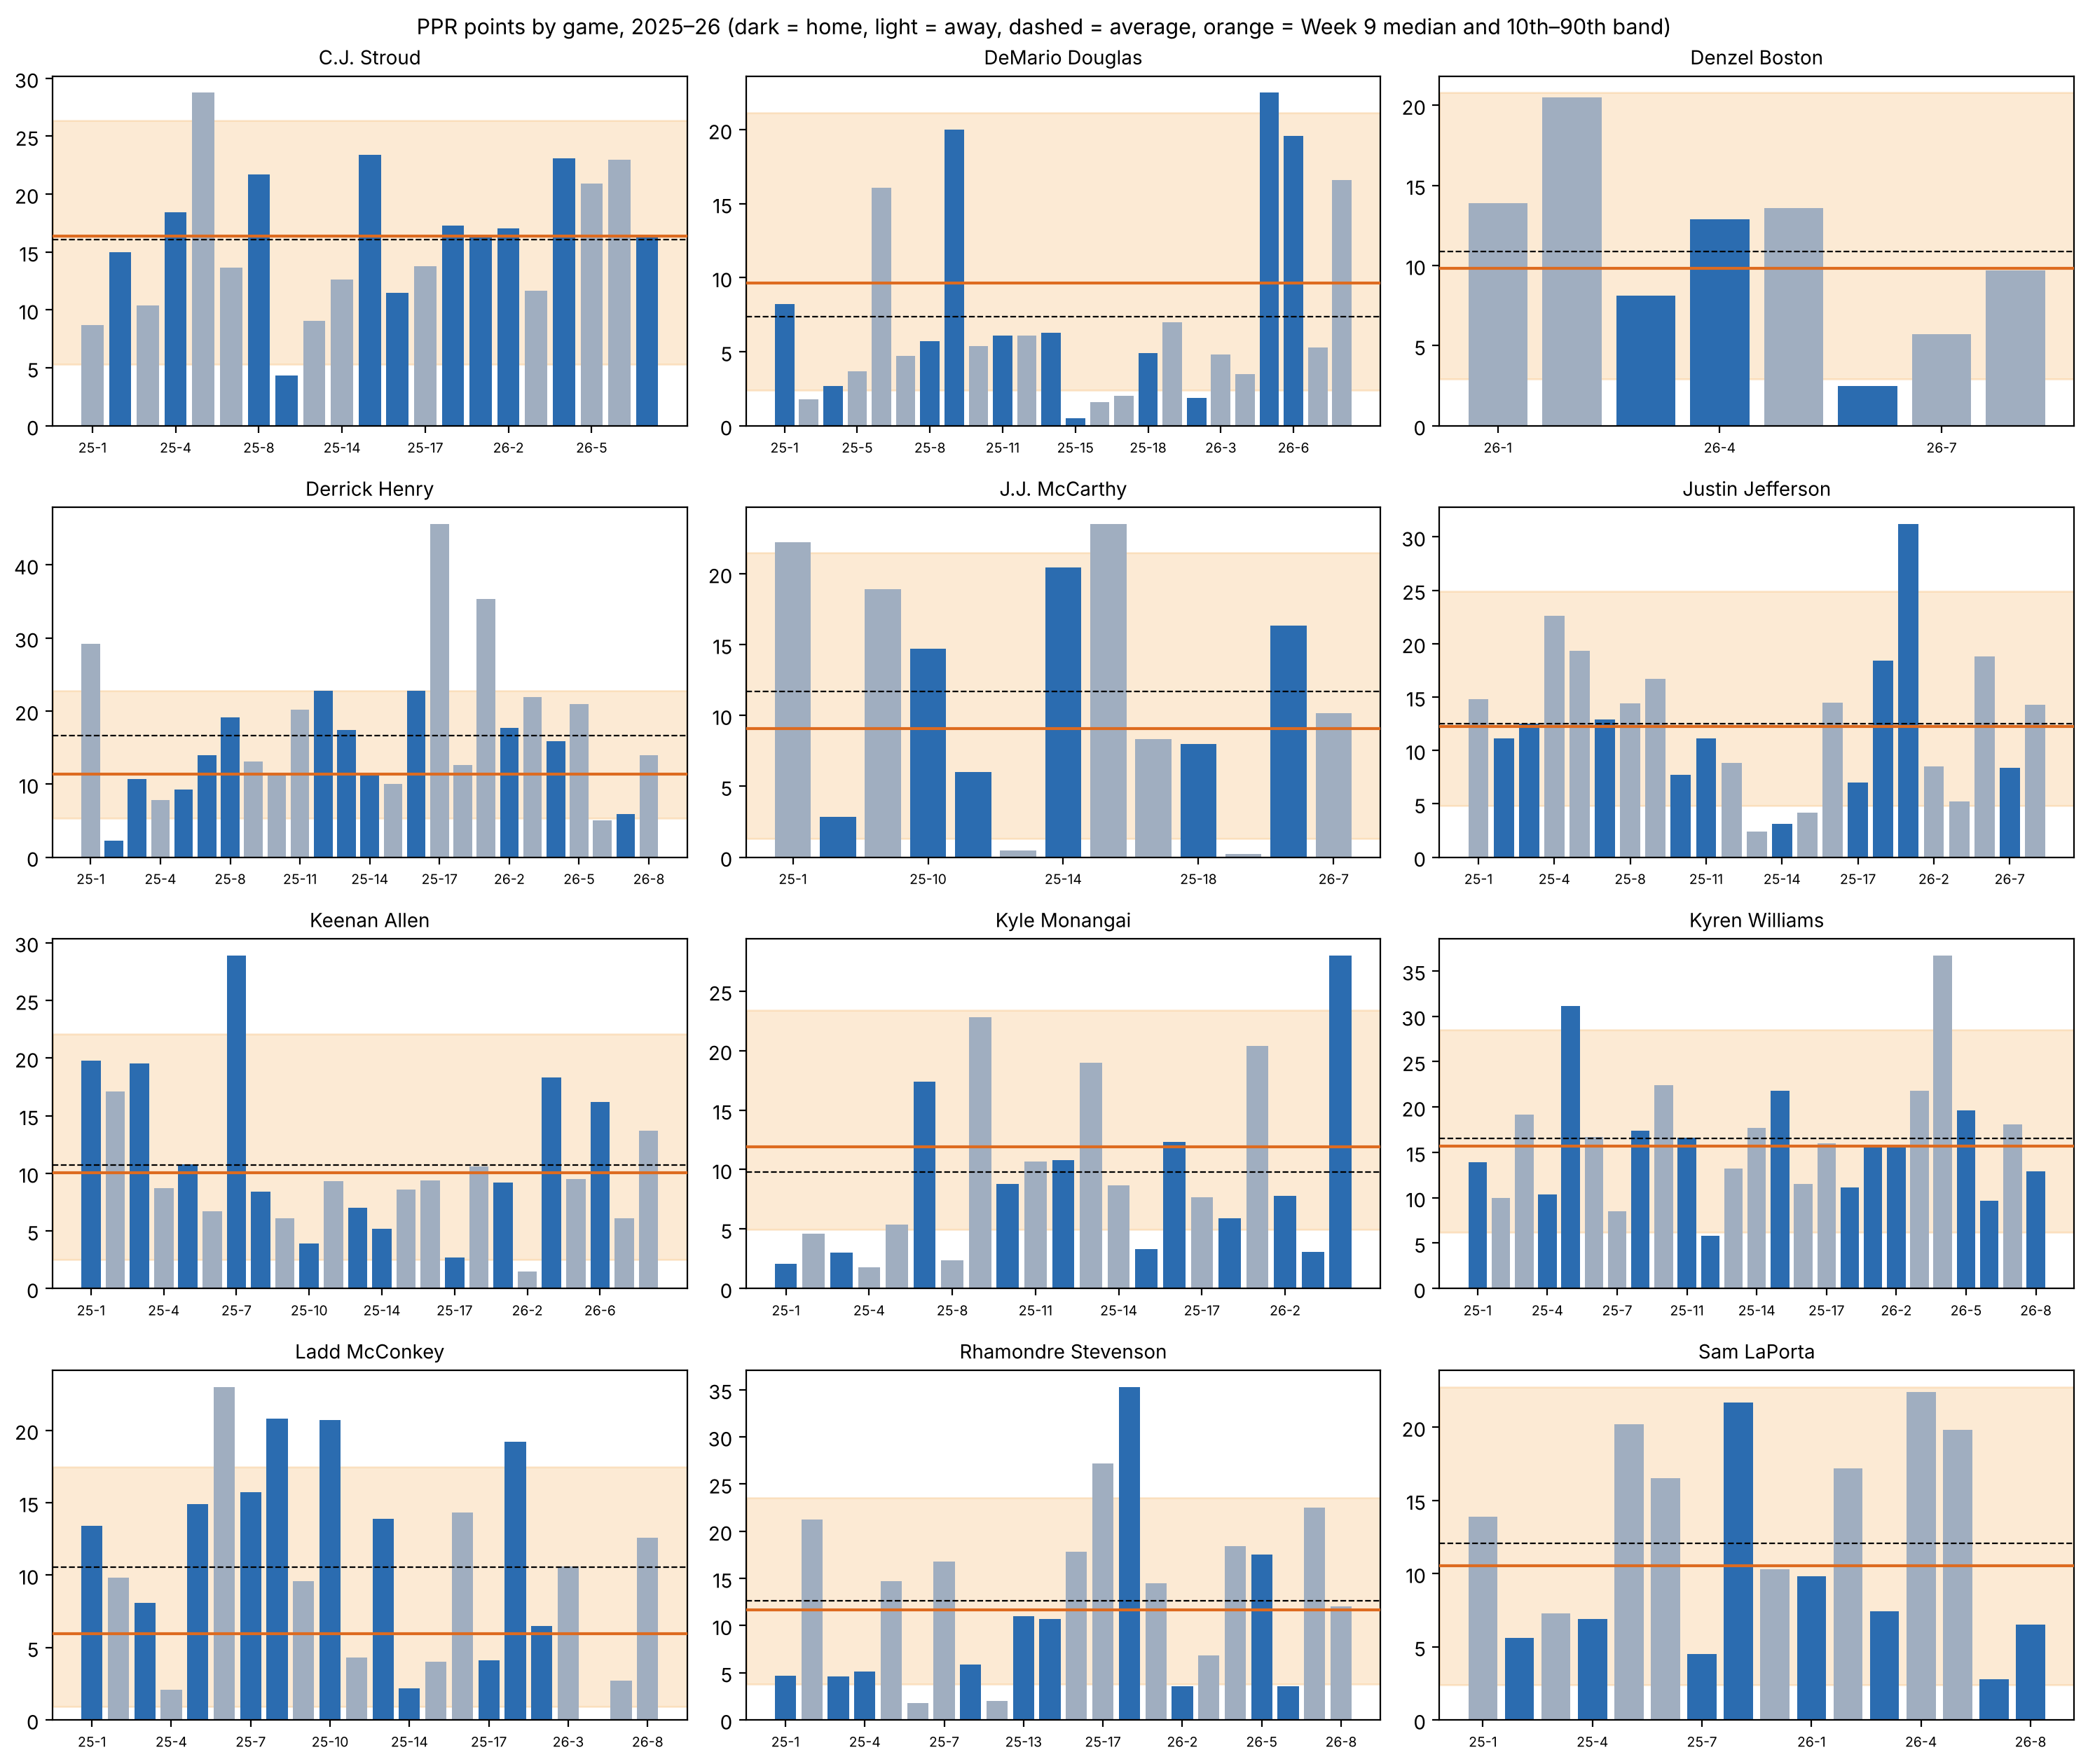

In [19]:
this_week = SKILL_TABLE.set_index("player_display_name")
nm = sorted(recent.player_display_name.unique())
rows_ = int(np.ceil(len(nm) / 3))
fig, axes = plt.subplots(rows_, 3, figsize=(15, 3.2 * rows_))
for ax, name in zip(axes.flat, nm):
    x = recent[recent.player_display_name == name].sort_values(["season", "week"])
    i = np.arange(len(x))
    if name in this_week.index:
        r = this_week.loc[name]
        ax.axhspan(r["floor"], r["ceiling"], color="#f6ad55", alpha=0.25, zorder=0)
        ax.axhline(r["median"], color="#dd6b20", lw=1.5, zorder=3)
    ax.bar(i, x.fp, color=np.where(x.home == 1, "#2b6cb0", "#a0aec0"), zorder=2)
    ax.axhline(x.fp.mean(), color="black", lw=0.8, ls="--", zorder=3)
    ax.set_title(name, fontsize=10)
    ax.set_xticks(i[::3]); ax.set_xticklabels([f"{s % 100}-{w}" for s, w in zip(x.season, x.week)][::3], fontsize=7)
for ax in list(axes.flat)[len(nm):]: ax.axis("off")
fig.suptitle("PPR points by game, 2025–26 (dark = home, light = away, dashed = average, orange = Week 9 median and 10th–90th band)", fontsize=11)
plt.tight_layout(); plt.show()

## 12. Lead RB vs. the defense he faces (the Henry/Jaguars question)
Raw points, every game since 2022: the lead back (most carries) vs. the D/ST he played against.

In [20]:
rb1 = hist_only(p.dropna(subset=["fp"])).query("position == 'RB'").sort_values("carries", ascending=False).groupby(["season", "week", "team"]).head(1)
pair = rb1.merge(dst.rename(columns={"team": "opponent_team", "opponent_team": "_t", "dst_pts": "opp_dst"}),
                 on=["season", "week", "opponent_team"])
pair["RB1 points"] = pd.cut(pair.fp, [-10, 8, 14, 20, 80], labels=["<8", "8–14", "14–20", "20+"])
print(f"{len(pair)} games | correlation {pair.fp.corr(pair.opp_dst):.2f} | Henry only: "
      f"{pair[pair.player_display_name == 'Derrick Henry'].pipe(lambda x: x.fp.corr(x.opp_dst)):.2f}")
pair.groupby("RB1 points", observed=True).opp_dst.agg(games="size", avg_opposing_DST="mean",
                                                    pct_DST_8plus=lambda s: 100 * (s >= 8).mean()).round(1)

2416 games | correlation -0.38 | Henry only: -0.44


,games,avg_opposing_DST,pct_DST_8plus
RB1 points,,,
<8,541,7.6,47.7
8–14,768,5.6,32.8
14–20,558,3.8,21.3
20+,549,1.6,10.7
